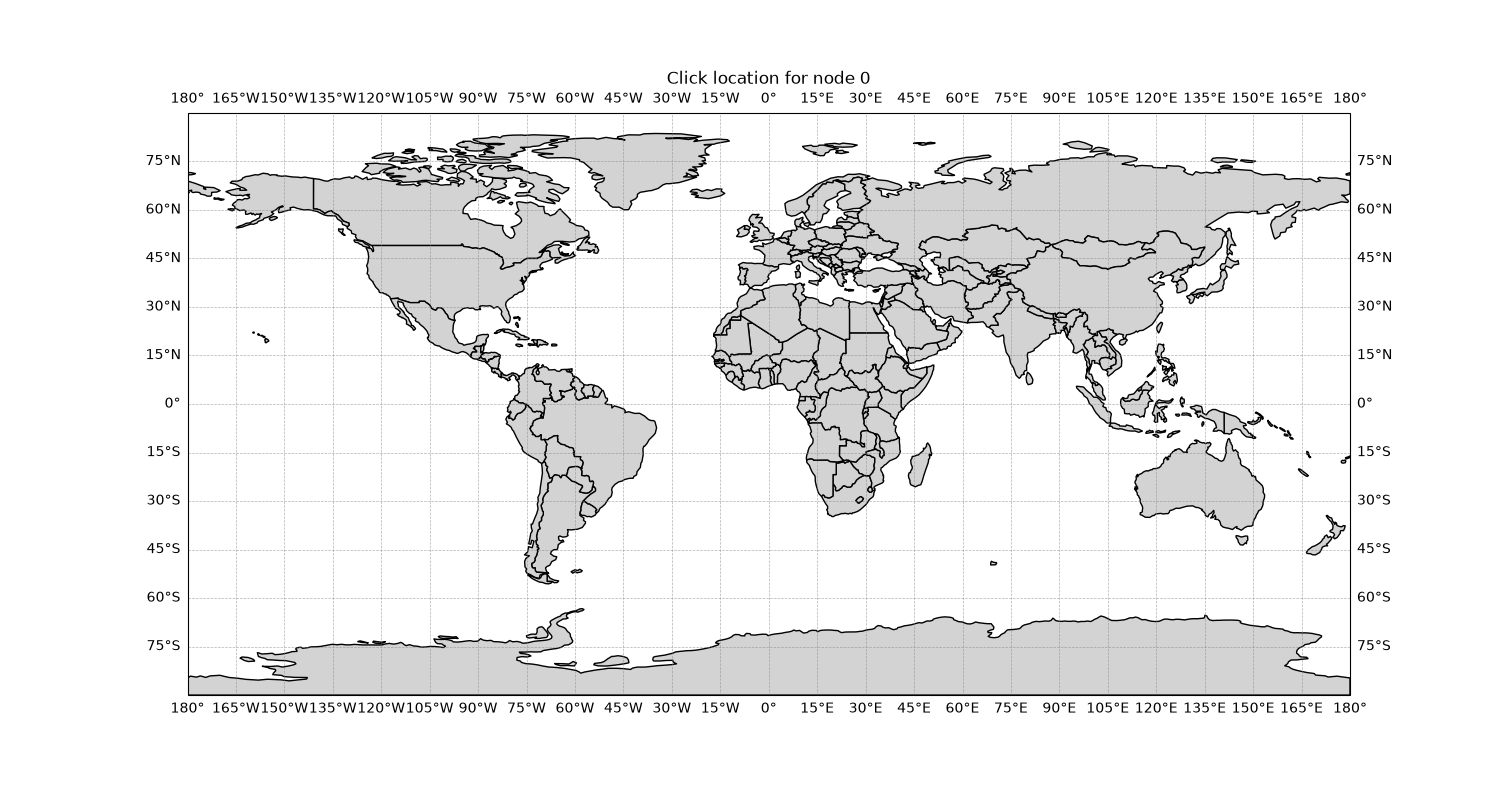

In [1]:
%matplotlib widget
import matplotlib.pyplot as plt
import geopandas as gpd
import networkx as nx
import cartopy.crs as ccrs
import matplotlib.ticker as mticker
from src.graph_utils import assign_properties, create_layered_graph

# World map
world = gpd.read_file(r"C:\Users\Drew\Documents\MyFiles\work\networks\110m_cultural\ne_110m_admin_0_countries.shp")

fig = plt.figure(figsize=(15, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
world.plot(ax=ax, color="lightgray", edgecolor="black", transform=ccrs.PlateCarree())
ax.set_global()
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color="gray", alpha=0.6, linestyle="--")
gl.xlocator = mticker.FixedLocator(range(-180, 181, 15))
gl.ylocator = mticker.FixedLocator(range(-90, 91, 15))

# Graph
layer_sizes = [4, 3, 3, 2, 2, 5, 2]
G, layers = create_layered_graph(layer_sizes)
pos = nx.multipartite_layout(G, subset_key='layer', align='vertical', scale=2)
layer_role_assign = {0: ['A'], 1: ['A', 'B'], 2: ['A', 'B', 'C'], 3: ['A', 'B', 'C'], 4: ['A', 'B', 'C'], 5: ['B', 'C'], 6: ['B', 'C'], 7: ['C'], 8: ['C']}
G = assign_properties(G, layer_sizes, layer_role_assign=layer_role_assign)

nodes = list(G.nodes)
positions = {}
current = 0
title = ax.set_title(f"Click location for node {nodes[current]}")
def onclick(event):
    global current

    if event.inaxes != ax:
        return

    if current >= len(nodes):
        return

    node = nodes[current]

    lon = event.xdata
    lat = event.ydata

    positions[node] = (lon, lat)

    # Draw point
    ax.scatter(lon, lat, color="red", s=40, zorder=5)

    # Label point
    ax.text(lon, lat, str(node), fontsize=9)

    print(f"{node}: ({lon:.3f}, {lat:.3f})")

    current += 1

    if current < len(nodes):
        ax.set_title(f"Click location for node {nodes[current]}")
    else:
        ax.set_title("Finished assigning nodes")
        fig.canvas.mpl_disconnect(cid)

    fig.canvas.draw()

cid = fig.canvas.mpl_connect("button_press_event", onclick)
plt.show()

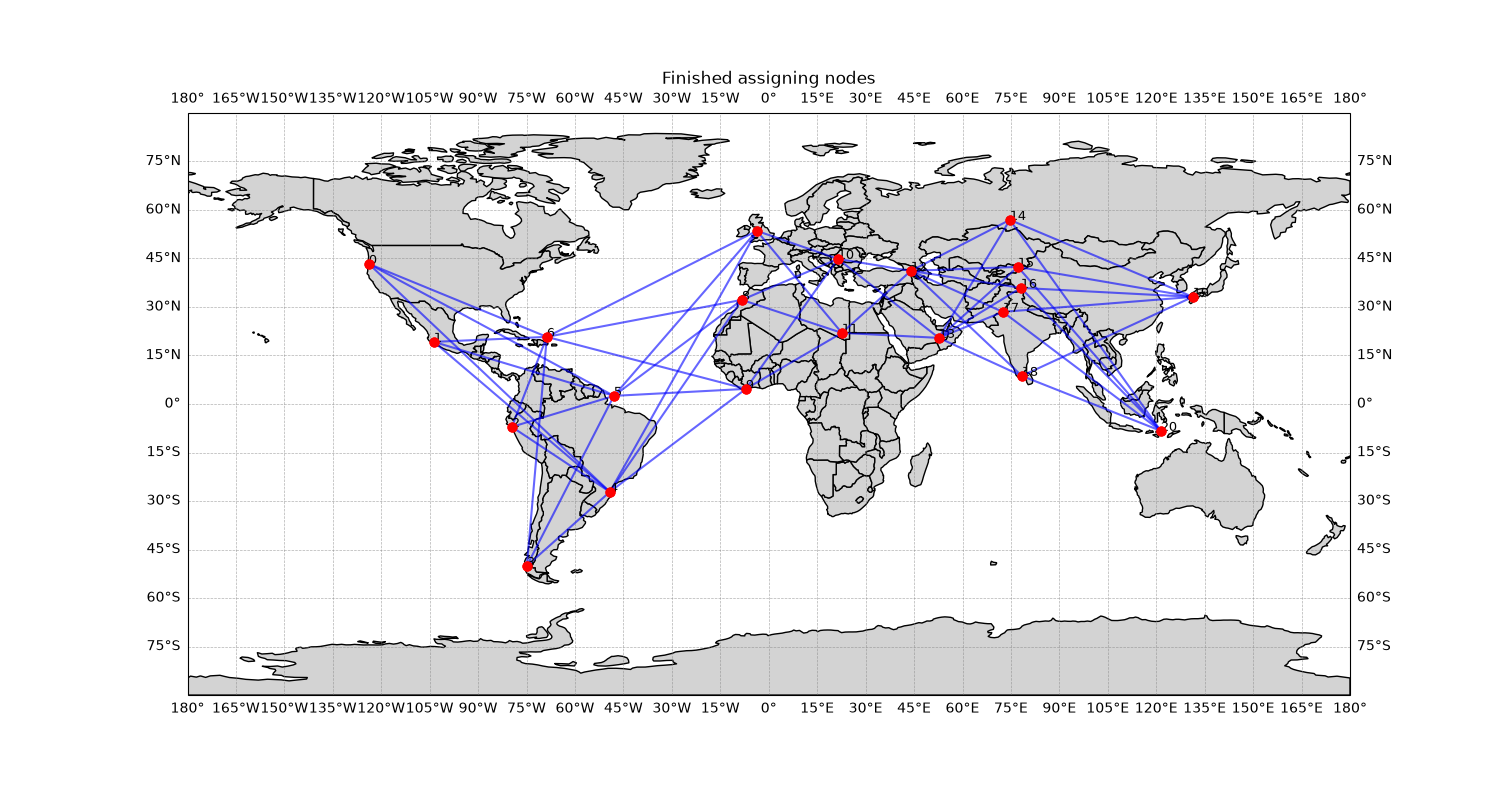

In [2]:
nx.set_node_attributes(G, positions, "pos")
def draw_graph(ax, G):
    pos = nx.get_node_attributes(G, "pos")

    # edges
    for u, v in G.edges():
        x1, y1 = pos[u]
        x2, y2 = pos[v]
        ax.plot([x1, x2], [y1, y2],
                transform=ccrs.PlateCarree(),
                color="blue", alpha=0.6)

    # nodes
    xs = [pos[n][0] for n in G.nodes()]
    ys = [pos[n][1] for n in G.nodes()]

    ax.scatter(xs, ys,
               transform=ccrs.PlateCarree(),
               color="red", s=40, zorder=5)

draw_graph(ax, G)
plt.show()
